# Optimización V2: predicción de `tiene_pareja`

Segunda ronda **exploratoria** sobre los mismos 20 participantes de la entrega V1. Diseño, candidatos y regla de
selección fijados antes de ejecutar (`docs/PREREGISTRO.md`).

* Por defecto el notebook **no reentrena** (`RECALCULAR = False`): carga resultados guardados y recalcula las
  métricas desde las predicciones fuera de muestra.
* Con `RECALCULAR = True` reejecuta con 2 repeticiones el mejor candidato V2 y comprueba que coincide con la caché.

In [2]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display
V2 = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path[:0] = [str(V2.parent / "src"), str(V2 / "src")]
import v2_utils as u
u.silenciar_avisos()
RECALCULAR = False
MET = V2 / "resultados" / "metricas"; GRAF = V2 / "resultados" / "graficas"
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200)
df = u.cargar_integrado(); y = df[u.TARGET].astype(int)
print("participantes:", len(df), "| con pareja:", int(y.sum()), "| sin pareja:", int((y == 0).sum()))

ModuleNotFoundError: No module named 'ml_utils'

## 1. Auditoría de la V1 (fase A)
Hallazgos principales: métricas V1 reproducibles; clase positiva = 1; el ROC-AUC del Dummy (0.419) es un
**artefacto de agregar predicciones entre particiones** (su constante cambia entre particiones: 7/16 o 8/16) y vale
exactamente 0.5 dentro de cada partición; `nunca_tuvo_relacion` revela el objetivo y se excluye en la V2.

In [ ]:
pd.read_csv(MET / "auditoria_v1.csv")

,tema,resultado,detalle
0,Metricas V1 reproducibles desde predicciones,OK,max dif = 1.1e-16
1,Clase positiva,OK,"tiene_pareja: 1 = si (n=9), 0 = no (n=11); pre..."
2,Precision/Recall/Brier coherentes con la defin...,OK,"Brier = media((p - y)^2), comprobado manualmen..."
3,Precision/Recall del Dummy,INFO,Dummy predice siempre 'no' (max p = 0.5000 <= ...
4,Particiones reconstruidas = particiones V1,OK,las probabilidades del Dummy coinciden exactam...
5,ROC-AUC del Dummy = 0.419 (no 0.5),EXPLICADO,AUC agrupado = 0.4192 en todas las repeticione...
6,Consecuencia para todos los modelos,IMPORTANTE,El mismo artefacto (cambio de proporcion de cl...
7,AUC por particion V1,INFO,musica_sola|Decision Tree=0.439; musica_sola|D...
8,nunca_tuvo_relacion revela el objetivo,EXCLUIDA EN V2,nunca_tuvo_relacion=1 -> tiene_pareja=0 en 3/3...
9,Faltantes de edad_primera_relacion_val,CONTROLADO,faltante en 3 casos = mismos que nunca_tuvo_re...


In [ ]:
pd.read_csv(MET / "auditoria_auc_dummy.csv").head(10)

,repeticion,particion,positivos_prueba,negativos_prueba,p_constante,auc_particion
0,0,0,2,2,0.4375,0.5
1,0,1,2,2,0.4375,0.5
2,0,2,2,2,0.4375,0.5
3,0,3,2,2,0.4375,0.5
4,0,4,1,3,0.5000,0.5
5,1,0,2,2,0.4375,0.5
6,1,1,2,2,0.4375,0.5
7,1,2,2,2,0.4375,0.5
8,1,3,2,2,0.4375,0.5
9,1,4,1,3,0.5000,0.5


## 2. Representación V2 y candidatos (fases B-D)
Codificación ordinal fija de respuestas de música con orden natural, categorías raras agrupadas (frecuencia ≥ 3 en
entrenamiento), filtro de redundancia |r| > 0.9 aprendido en entrenamiento y 12 familias con rejillas pequeñas,
más una **selección automática anidada** que elige la familia dentro de la CV interna.

In [ ]:
for esc, spec in u.ESCENARIOS_V2.items():
    print(f"{esc:18s}", {k: len(v) for k, v in spec.items()}, "->", len(u.columnas(spec)), "preguntas")
print("Excluidas:", u.EXCLUIDAS)

relaciones         {'num': 2, 'bin': 1, 'ord': 0, 'cat': 1, 'multi': 9} -> 13 preguntas
musica_sola        {'num': 2, 'bin': 6, 'ord': 7, 'cat': 0, 'multi': 9} -> 24 preguntas
relaciones_musica  {'num': 4, 'bin': 7, 'ord': 7, 'cat': 1, 'multi': 18} -> 37 preguntas
Excluidas: {'nunca_tuvo_relacion': 'implica logicamente tiene_pareja = 0 (revela el objetivo)'}


## 3. Resultados: V1 vs V2 vs Dummy
Media y desviación entre 10 repeticiones de CV anidada (5 particiones, semilla 42, **mismas particiones que la V1**).

In [ ]:
r = pd.read_csv(MET / "comparativo_v1_v2.csv")
cols = ["ronda", "escenario", "modelo", "balanced_accuracy_media", "balanced_accuracy_std", "f1_macro_media",
        "accuracy_media", "roc_auc_por_particion_media", "roc_auc_media", "brier_media"]
r[cols].sort_values("balanced_accuracy_media", ascending=False).round(3).head(20)

,ronda,escenario,modelo,balanced_accuracy_media,balanced_accuracy_std,f1_macro_media,accuracy_media,roc_auc_por_particion_media,roc_auc_media,brier_media
47,V2,relaciones_musica,SVM RBF,0.707,0.096,0.707,0.715,0.855,0.825,0.183
46,V2,relaciones_musica,SVM lineal,0.693,0.102,0.692,0.700,0.793,0.742,0.218
59,V2,relaciones_musica,Seleccion automatica anidada,0.686,0.088,0.684,0.690,0.785,0.762,0.204
30,V2,musica_sola,SVM lineal,0.581,0.074,0.566,0.575,0.655,0.605,0.264
15,V2,relaciones,SVM RBF,0.574,0.108,0.571,0.585,0.730,0.670,0.227
33,V2,musica_sola,PCA + LogReg,0.563,0.092,0.561,0.570,0.575,0.561,0.249
49,V2,relaciones_musica,PCA + LogReg,0.562,0.058,0.560,0.565,0.568,0.484,0.261
31,V2,musica_sola,SVM RBF,0.553,0.092,0.536,0.570,0.745,0.627,0.232
14,V2,relaciones,SVM lineal,0.526,0.098,0.515,0.525,0.548,0.538,0.317
43,V2,musica_sola,Seleccion automatica anidada,0.512,0.085,0.496,0.515,0.620,0.572,0.257


In [ ]:
pd.read_csv(MET / "comparacion_final_anterior_nuevo_dummy.csv").round(3)

,rol,id,escenario,modelo,accuracy,balanced_accuracy,f1_macro,precision,recall,roc_auc,roc_auc_por_particion,brier,balanced_accuracy_std
0,"Mejor modelo anterior (V1, regla común)",V1 | musica_sola | Decision Tree,musica_sola,Decision Tree,0.470,0.461,0.450,0.406,0.367,0.434,0.439,0.392,0.077
1,Modelo oficial V1 (Relaciones + Música),V1 | relaciones_musica | Decision Tree,relaciones_musica,Decision Tree,0.405,0.396,0.389,0.316,0.311,0.363,0.404,0.438,0.086
2,Mejor modelo nuevo (V2),V2 | relaciones_musica | SVM RBF,relaciones_musica,SVM RBF,0.715,0.707,0.707,0.729,0.622,0.825,0.855,0.183,0.096
3,Dummy Classifier (baseline),V1 | relaciones | Dummy (prior),relaciones,Dummy (prior),0.550,0.500,0.355,0.000,0.000,0.419,0.500,0.253,0.000
4,Selección automática anidada V2 (Relaciones),V2 | relaciones | Seleccion automatica anidada,relaciones,Seleccion automatica anidada,0.470,0.472,0.464,0.429,0.489,0.521,0.548,0.277,0.116
5,Selección automática anidada V2 (Música),V2 | musica_sola | Seleccion automatica anidada,musica_sola,Seleccion automatica anidada,0.515,0.512,0.496,0.438,0.478,0.572,0.620,0.257,0.085
6,Selección automática anidada V2 (Relaciones + ...,V2 | relaciones_musica | Seleccion automatica ...,relaciones_musica,Seleccion automatica anidada,0.690,0.686,0.684,0.692,0.644,0.762,0.785,0.204,0.088


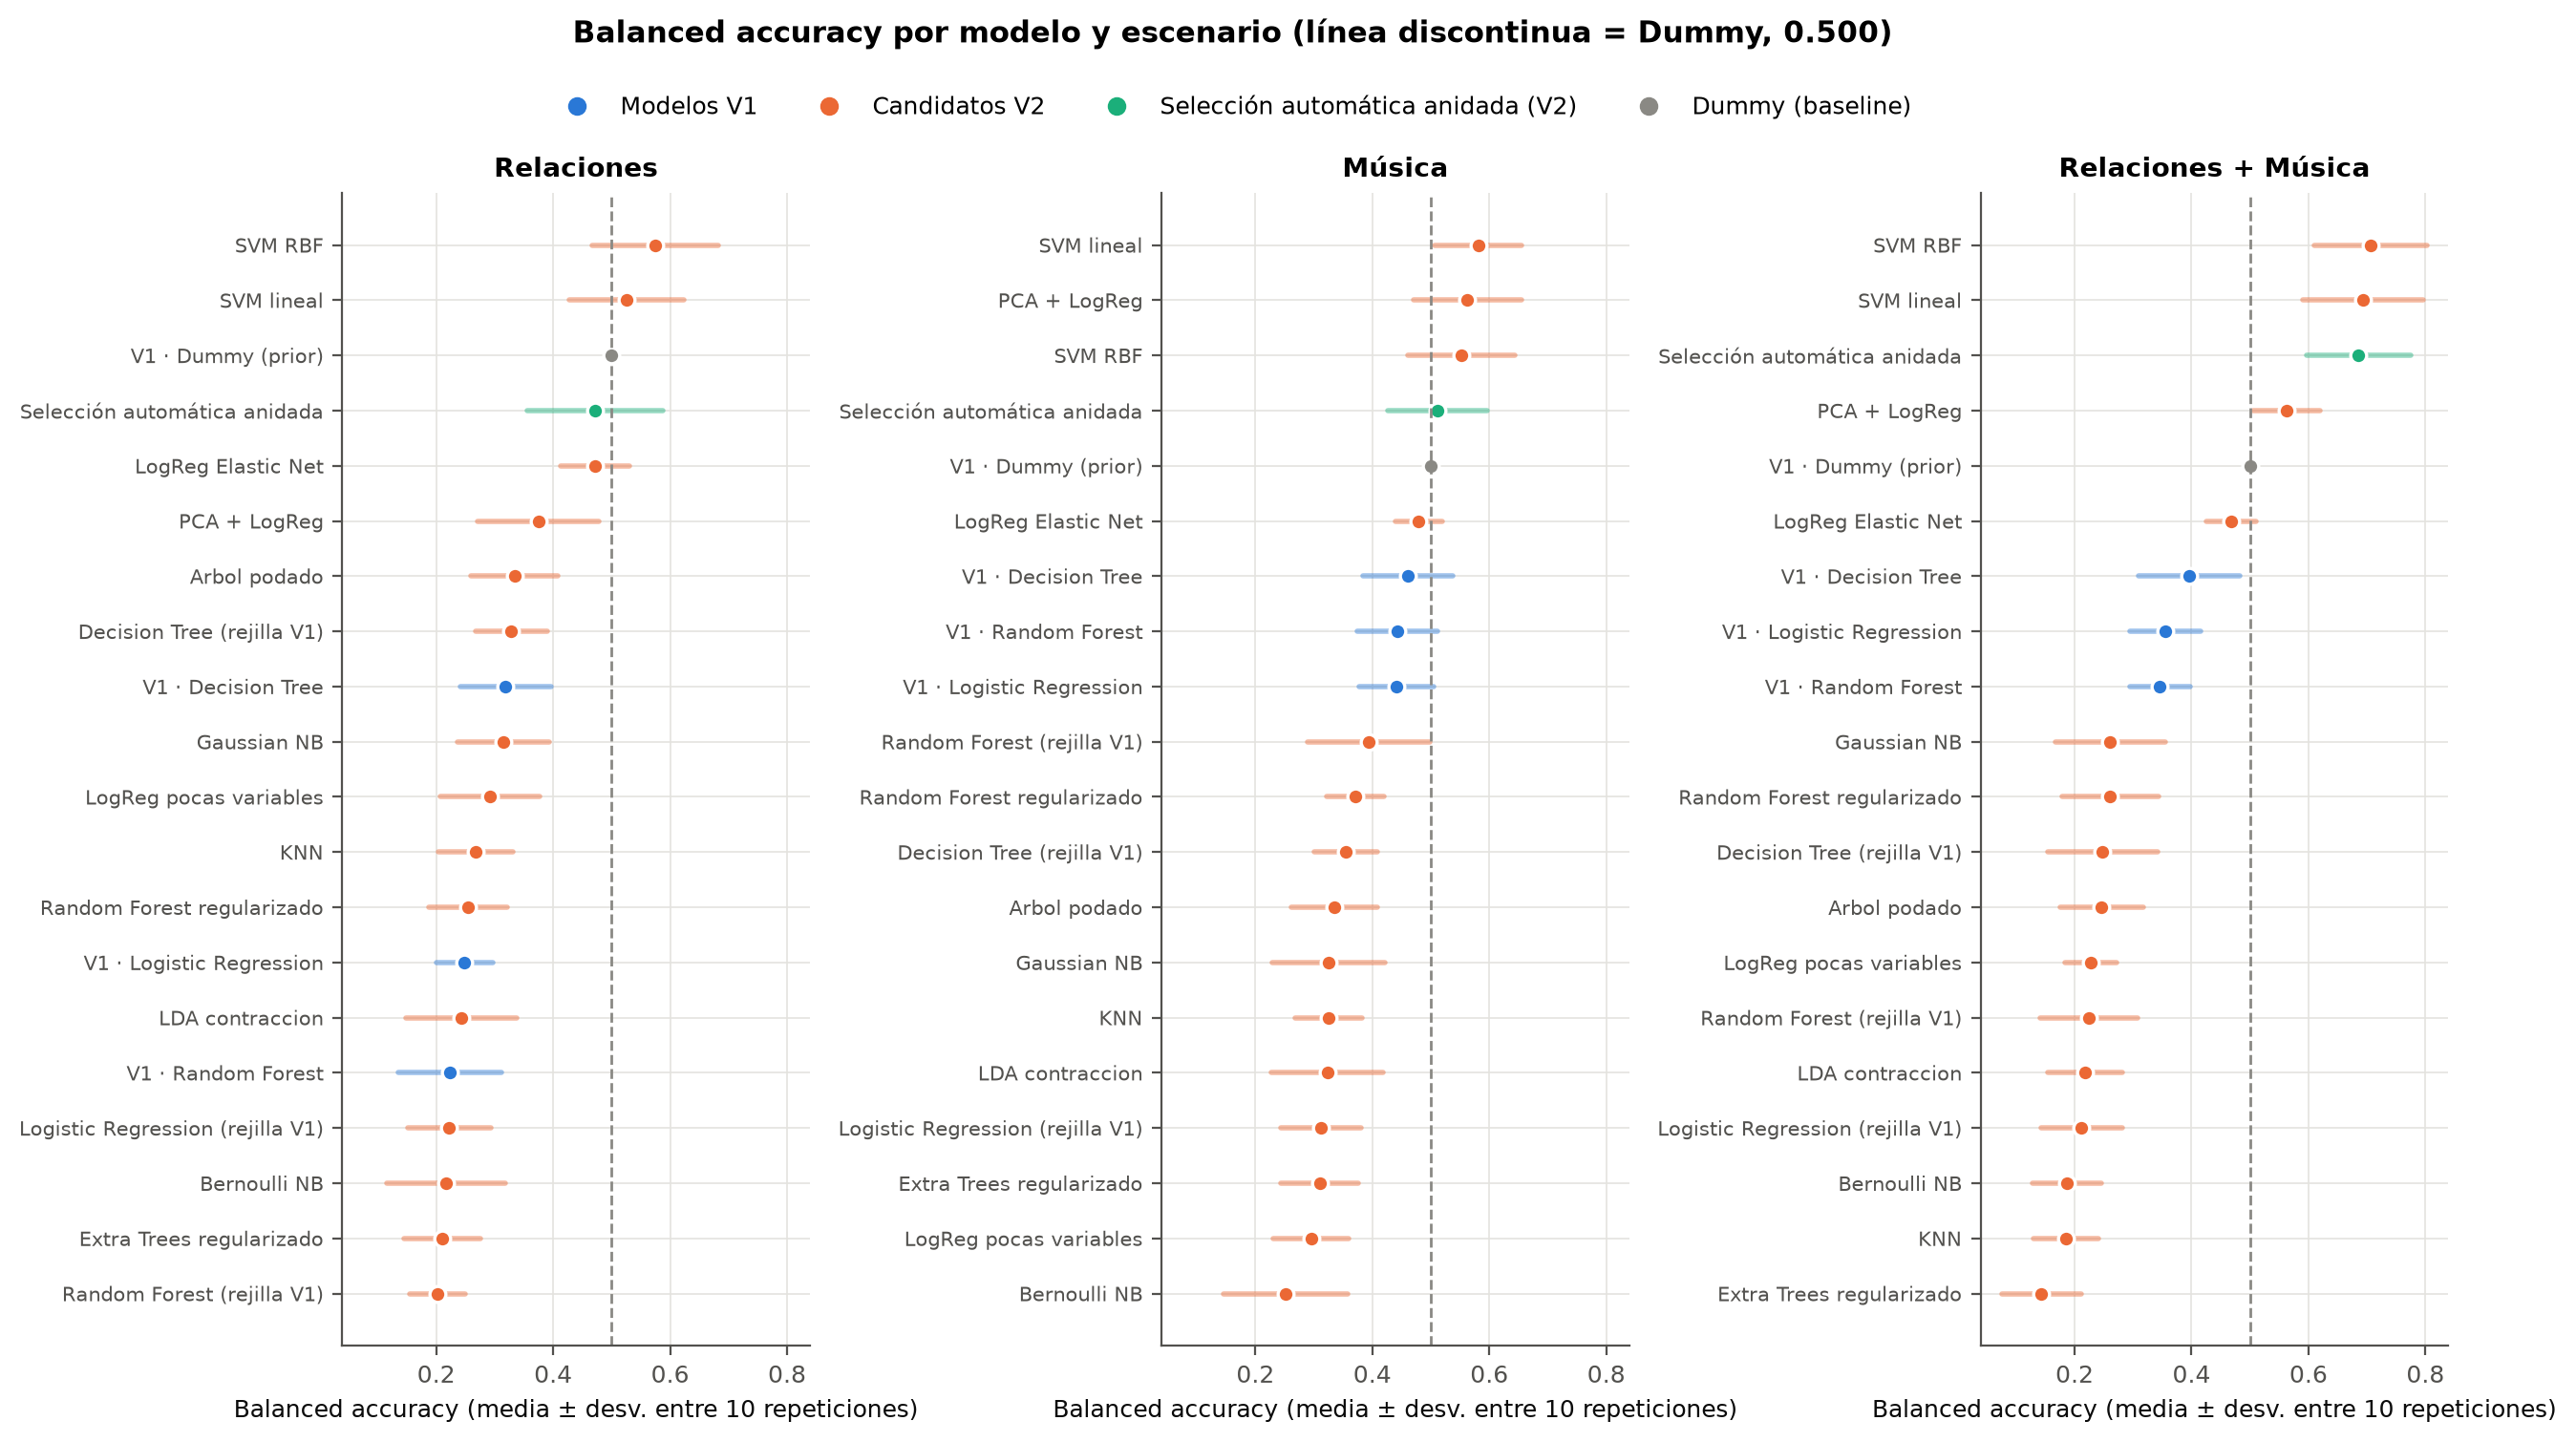

In [ ]:
display(Image(GRAF / "01_comparacion_balanced_accuracy.png", width=950))

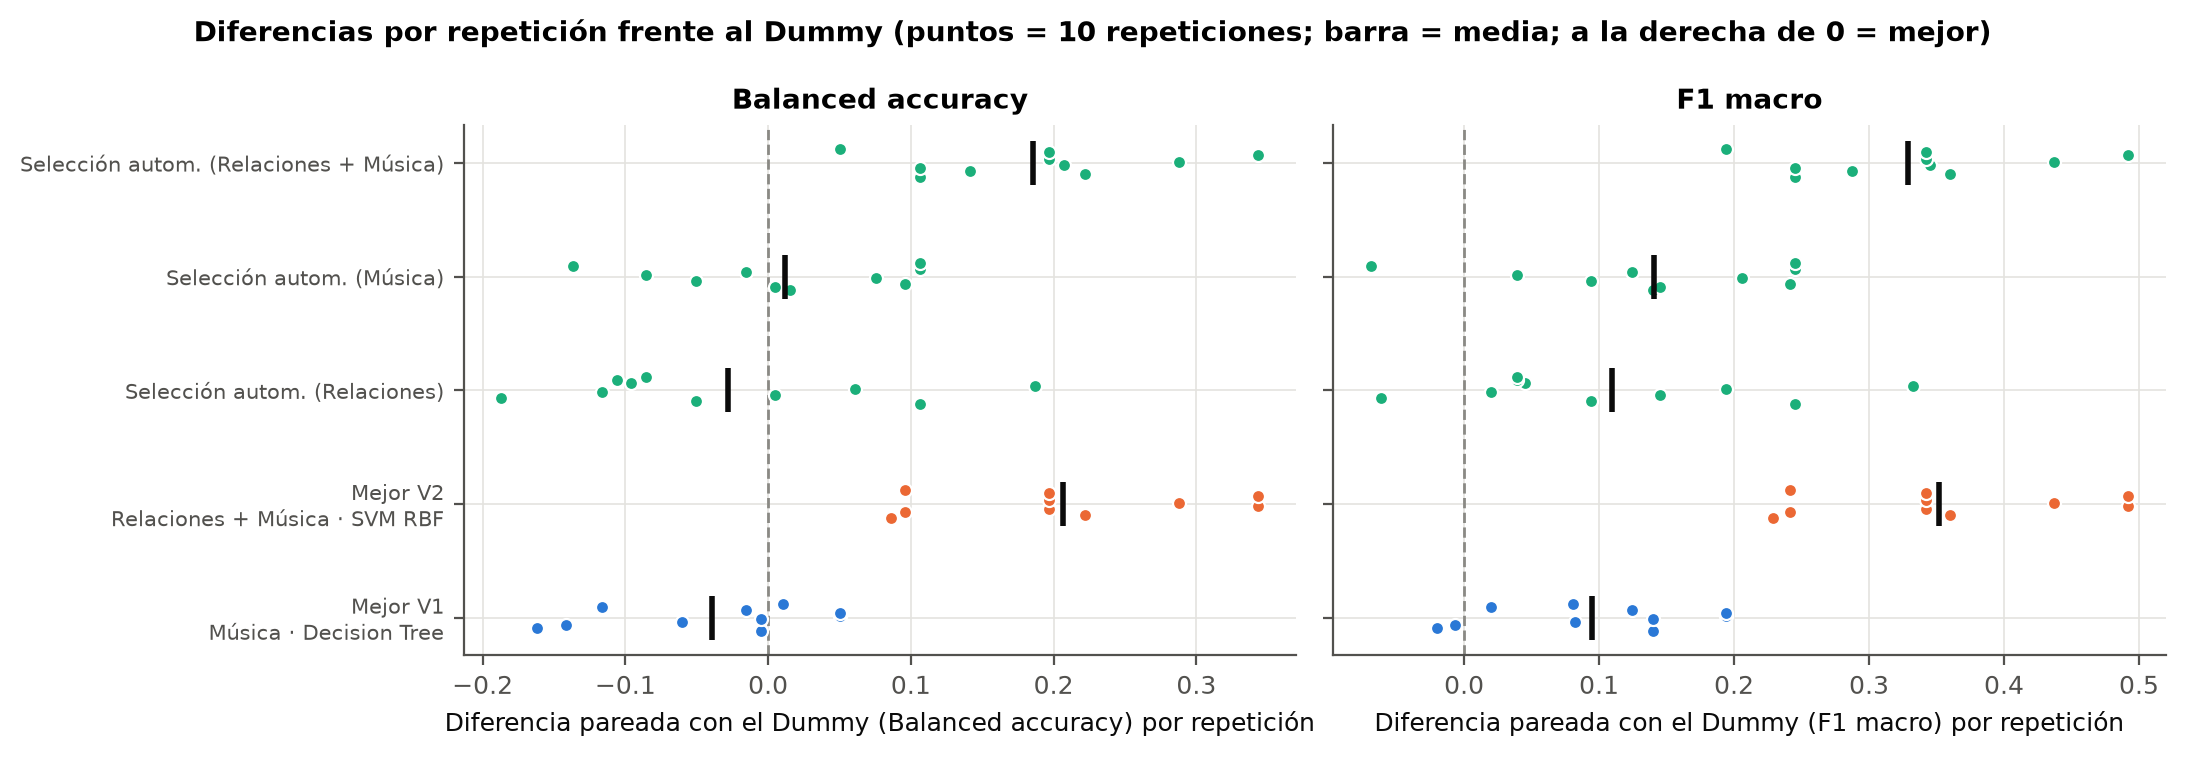

In [ ]:
display(Image(GRAF / "02_diferencias_pareadas_vs_dummy.png", width=950))

### Recalcular métricas desde las predicciones guardadas

In [ ]:
oof = pd.read_csv(MET / "predicciones_fuera_de_muestra_v2.csv")
rep = pd.read_csv(MET / "metricas_por_repeticion_v2.csv").set_index(["escenario", "modelo", "repeticion"])
dif = 0.0
for (esc, mod), g in oof.groupby(["escenario", "modelo"]):
    P = np.vstack([g[g.repeticion == k].proba_si.to_numpy() for k in range(10)])
    F = np.vstack([g[g.repeticion == k].particion.to_numpy() for k in range(10)])
    m = u.metricas_rep(y, P, F).set_index("repeticion")
    dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
print("máxima diferencia al recalcular:", dif)

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max(

máxima diferencia al recalcular: 0.0


/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))
/var/folders/qn/2m37nxd1467fj5rf36rcdcdr0000gn/T/ipykernel_5737/473204921.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  dif = max(dif, float((m[u.METRICAS_V2] - rep.loc[(esc, mod)][u.METRICAS_V2]).abs().max().max()))


## 4. Robustez (fase E)
### 4.1 Pruebas de permutaciones (CV anidada completa en cada permutación)
La prueba de la **selección automática anidada** es la más honesta: incluye la elección de familia dentro de cada
partición, así que su p-valor no se beneficia de haber elegido el mejor de muchos candidatos.

In [ ]:
v = json.loads((MET / "veredicto_v2.json").read_text())
pd.DataFrame({k: {"modelo": x["modelo"], "escenario": x["escenario"], "n_perm": x["n_permutaciones"],
                  "reps": x["repeticiones_cv"], "BA_obs": x["observado"]["balanced_accuracy"],
                  "BA_nula_media": x["media_nula"]["balanced_accuracy"], "p_BA": x["p_valor"]["balanced_accuracy"],
                  "p_Brier": x["p_valor"]["brier"]} for k, x in v["permutaciones"].items()}).T

,modelo,escenario,n_perm,reps,BA_obs,BA_nula_media,p_BA,p_Brier
mejor V2,SVM RBF,relaciones_musica,200,2,0.654,0.4604,0.0299,0.0199
seleccion automatica relaciones,Seleccion automatica anidada,relaciones,40,1,0.6061,0.4677,0.1463,0.0488
seleccion automatica musica_sola,Seleccion automatica anidada,musica_sola,40,1,0.5152,0.4802,0.3171,0.3902
seleccion automatica relaciones_musica,Seleccion automatica anidada,relaciones_musica,100,2,0.6641,0.4843,0.0891,0.0693


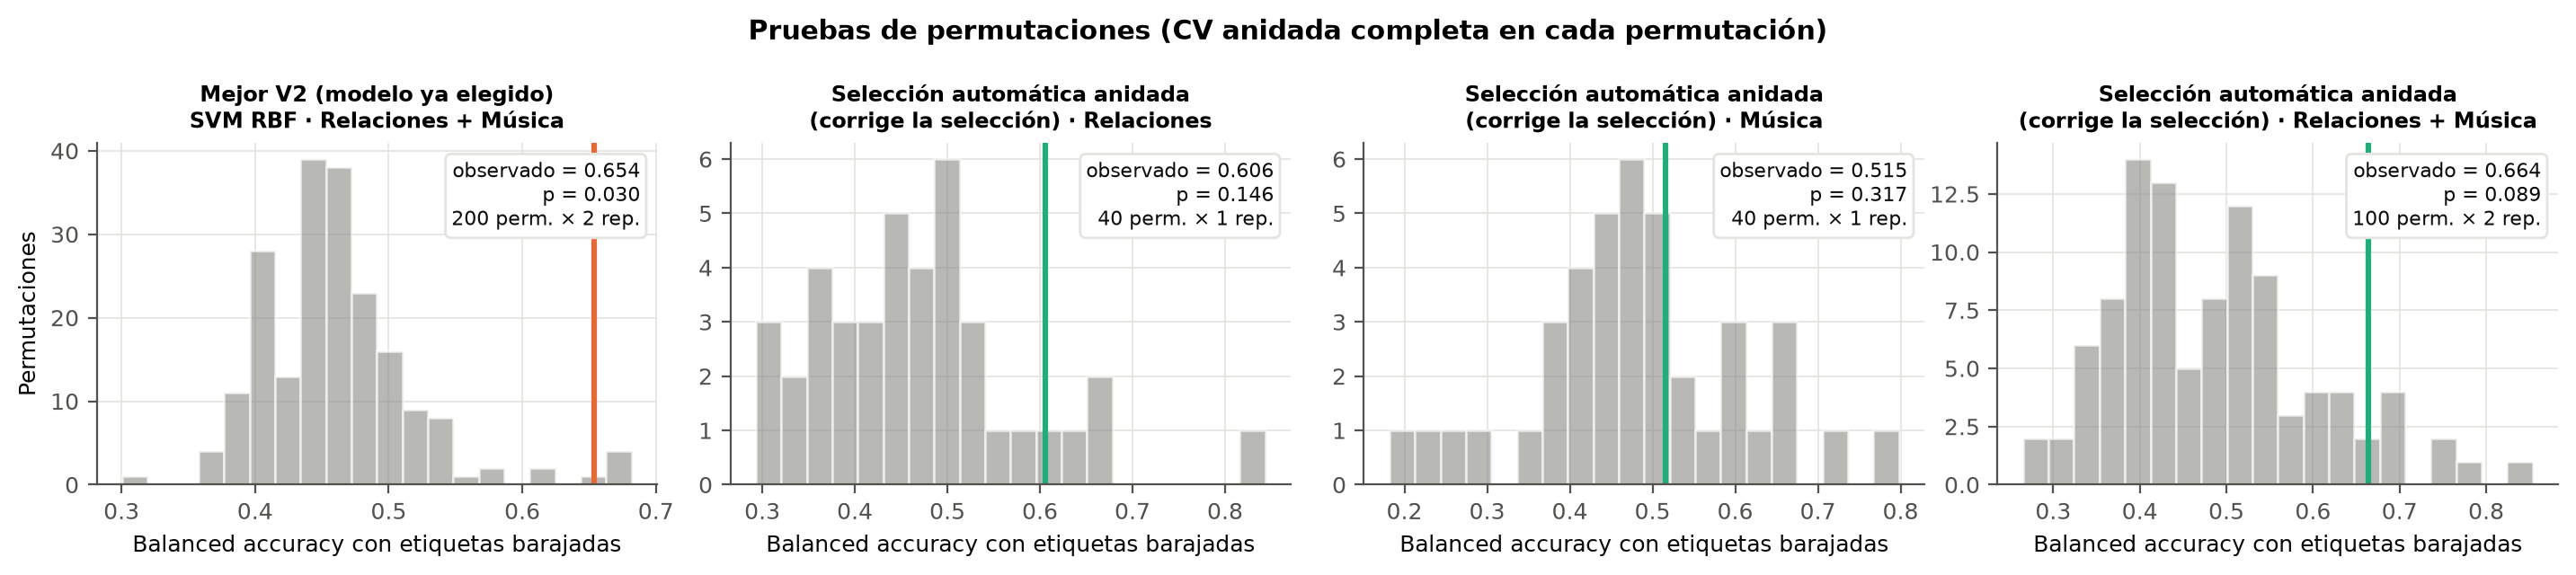

In [ ]:
display(Image(GRAF / "03_pruebas_permutaciones.png", width=950))

### 4.2 Diagnóstico del anti-aprendizaje
Los clasificadores basados en distancias/centroides quedan **muy por debajo del azar** y los SVM con calibración
sigmoide interna **muy por encima**: la calibración aprende (solo con entrenamiento) una pendiente invertida. El
control con ruido puro descarta que sea un artefacto mecánico de la CV; la prueba de similitud muestra que en estos
datos las personas se parecen más a las de la **otra** clase que a las de la suya.

In [ ]:
pd.read_csv(MET / "diagnostico_platt_particiones.csv").groupby("modelo")[["invierte_senal", "auc_svc_sin_calibrar", "auc_tras_calibrar"]].mean().round(3)

,invierte_senal,auc_svc_sin_calibrar,auc_tras_calibrar
modelo,,,
SVM RBF,0.9,0.117,0.783
SVM lineal,0.9,0.200,0.700


In [ ]:
d = pd.read_csv(MET / "diagnostico_antiaprendizaje.csv")
d.groupby(["datos", "modelo"]).balanced_accuracy.agg(["mean", "min", "max"]).round(3)

mean    min    max
datos           modelo                                 
ruido binario   Bernoulli NB        0.533  0.302  0.681
                KNN                 0.517  0.300  0.654
                LogReg Elastic Net  0.524  0.413  0.719
                SVM RBF             0.514  0.466  0.651
                SVM lineal          0.512  0.403  0.573
ruido gaussiano Bernoulli NB        0.494  0.331  0.609
                KNN                 0.456  0.337  0.579
                LogReg Elastic Net  0.440  0.378  0.479
                SVM RBF             0.497  0.442  0.589
                SVM lineal          0.493  0.414  0.572

In [ ]:
pd.read_csv(MET / "diagnostico_similitud_inversa.csv").round(4)

,escenario,similitud_intra_menos_inter,media_nula,p_unilateral_inversa,n_permutaciones
0,relaciones,-0.0403,0.0002,0.0278,10000
1,musica_sola,-0.0424,-0.0003,0.0231,10000
2,relaciones_musica,-0.0406,0.0001,0.0019,10000


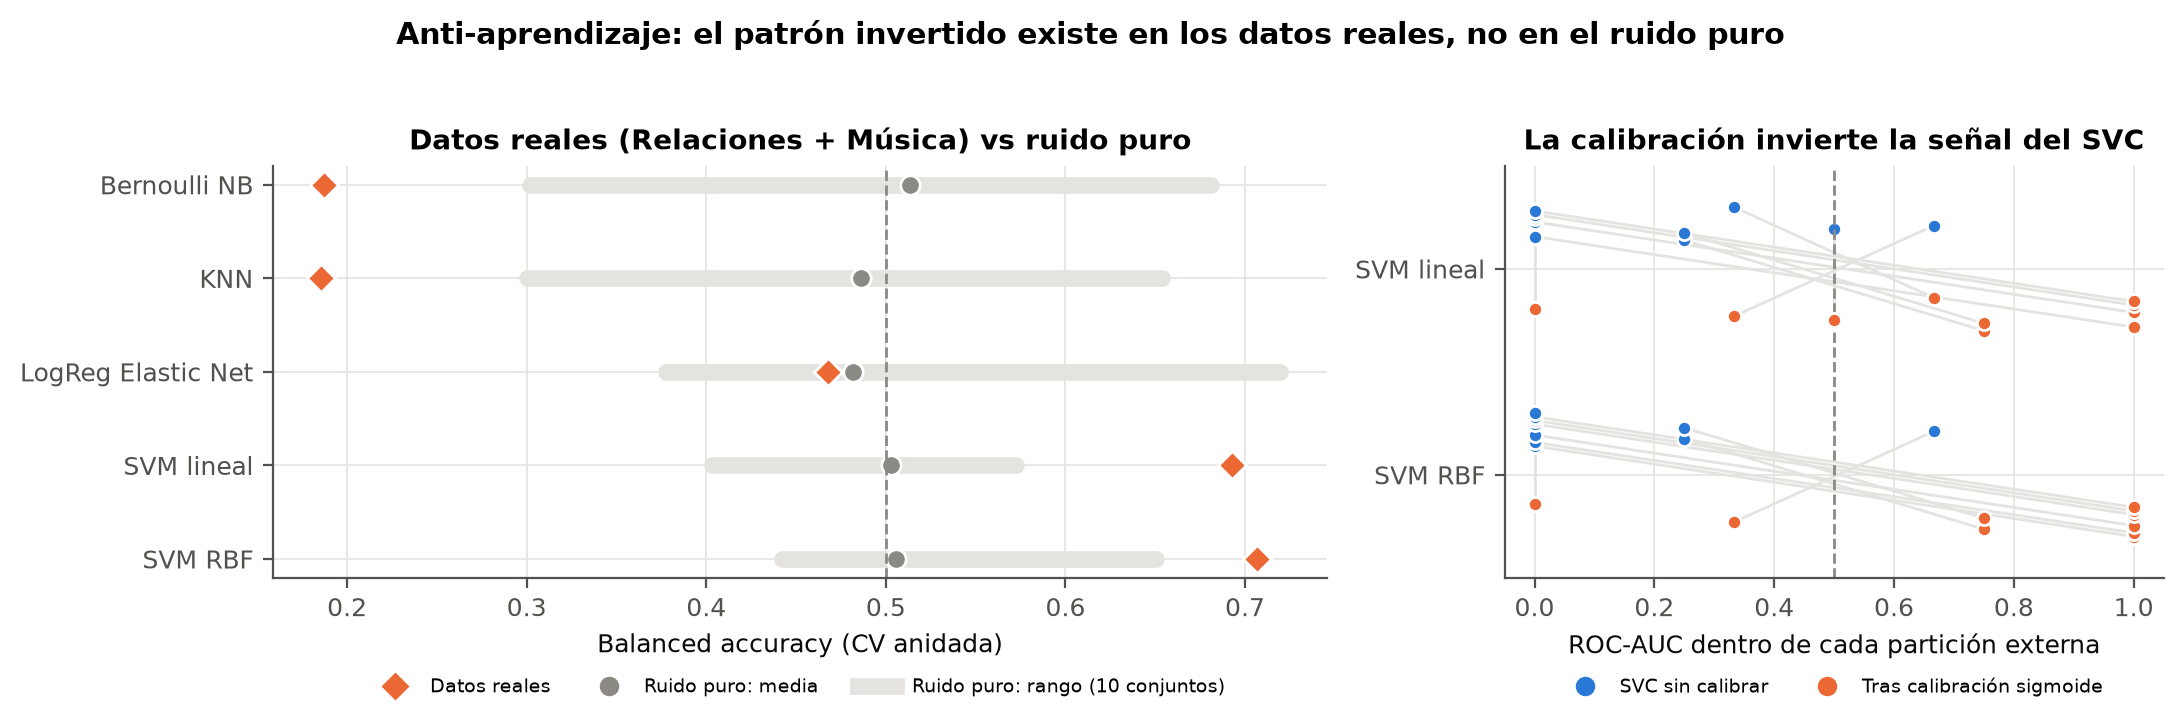

In [ ]:
display(Image(GRAF / "07_antiaprendizaje.png", width=950))

### 4.3 Estabilidad, errores y efecto de la representación

In [ ]:
c = pd.read_csv(MET / "comparaciones_pareadas_v2.csv")
c[c.metrica.isin(["balanced_accuracy", "brier"]) & c.comparacion.str.contains("vs Dummy|vs mejor V1|vs modelo oficial")].round(3)

,comparacion,A,B,metrica,media_A,media_B,diferencia_media,std_diferencia,min_diferencia,max_diferencia,repeticiones_A_mejor,empates,repeticiones
0,mejor V2 vs Dummy,V2 | relaciones_musica | SVM RBF,V1 | relaciones | Dummy (prior),balanced_accuracy,0.707,0.500,0.207,0.096,0.086,0.343,10,0,10
5,mejor V2 vs Dummy,V2 | relaciones_musica | SVM RBF,V1 | relaciones | Dummy (prior),brier,0.183,0.253,-0.070,0.024,-0.111,-0.028,10,0,10
6,mejor V1 vs Dummy,V1 | musica_sola | Decision Tree,V1 | relaciones | Dummy (prior),balanced_accuracy,0.461,0.500,-0.039,0.077,-0.162,0.051,3,0,10
11,mejor V1 vs Dummy,V1 | musica_sola | Decision Tree,V1 | relaciones | Dummy (prior),brier,0.392,0.253,0.139,0.067,0.055,0.268,0,0,10
12,mejor V2 vs mejor V1,V2 | relaciones_musica | SVM RBF,V1 | musica_sola | Decision Tree,balanced_accuracy,0.707,0.461,0.246,0.109,0.086,0.384,10,0,10
17,mejor V2 vs mejor V1,V2 | relaciones_musica | SVM RBF,V1 | musica_sola | Decision Tree,brier,0.183,0.392,-0.209,0.070,-0.332,-0.113,10,0,10
18,mejor V2 vs modelo oficial V1,V2 | relaciones_musica | SVM RBF,V1 | relaciones_musica | Decision Tree,balanced_accuracy,0.707,0.396,0.310,0.126,0.136,0.561,10,0,10
23,mejor V2 vs modelo oficial V1,V2 | relaciones_musica | SVM RBF,V1 | relaciones_musica | Decision Tree,brier,0.183,0.438,-0.254,0.055,-0.340,-0.178,10,0,10
24,seleccion automatica (relaciones) vs Dummy,V2 | relaciones | Seleccion automatica anidada,V1 | relaciones | Dummy (prior),balanced_accuracy,0.472,0.500,-0.028,0.116,-0.187,0.187,4,0,10
29,seleccion automatica (relaciones) vs Dummy,V2 | relaciones | Seleccion automatica anidada,V1 | relaciones | Dummy (prior),brier,0.277,0.253,0.024,0.046,-0.032,0.112,4,0,10


In [ ]:
e = pd.read_csv(MET / "estabilidad_seleccion_v2.csv")
e[(e.escenario == v["mejor_v2"]["escenario"]) & (e.modelo == "Seleccion automatica anidada") & (e.tipo == "familia")]

,escenario,modelo,tipo,valor,frecuencia
2463,relaciones_musica,Seleccion automatica anidada,familia,SVC-rbf,0.78
2464,relaciones_musica,Seleccion automatica anidada,familia,SVC-linear,0.12
2465,relaciones_musica,Seleccion automatica anidada,familia,PCA+LogisticRegression,0.04
2466,relaciones_musica,Seleccion automatica anidada,familia,LogisticRegression,0.02
2467,relaciones_musica,Seleccion automatica anidada,familia,LogisticRegression+SelectKBest,0.02
2468,relaciones_musica,Seleccion automatica anidada,familia,DecisionTreeClassifier,0.02


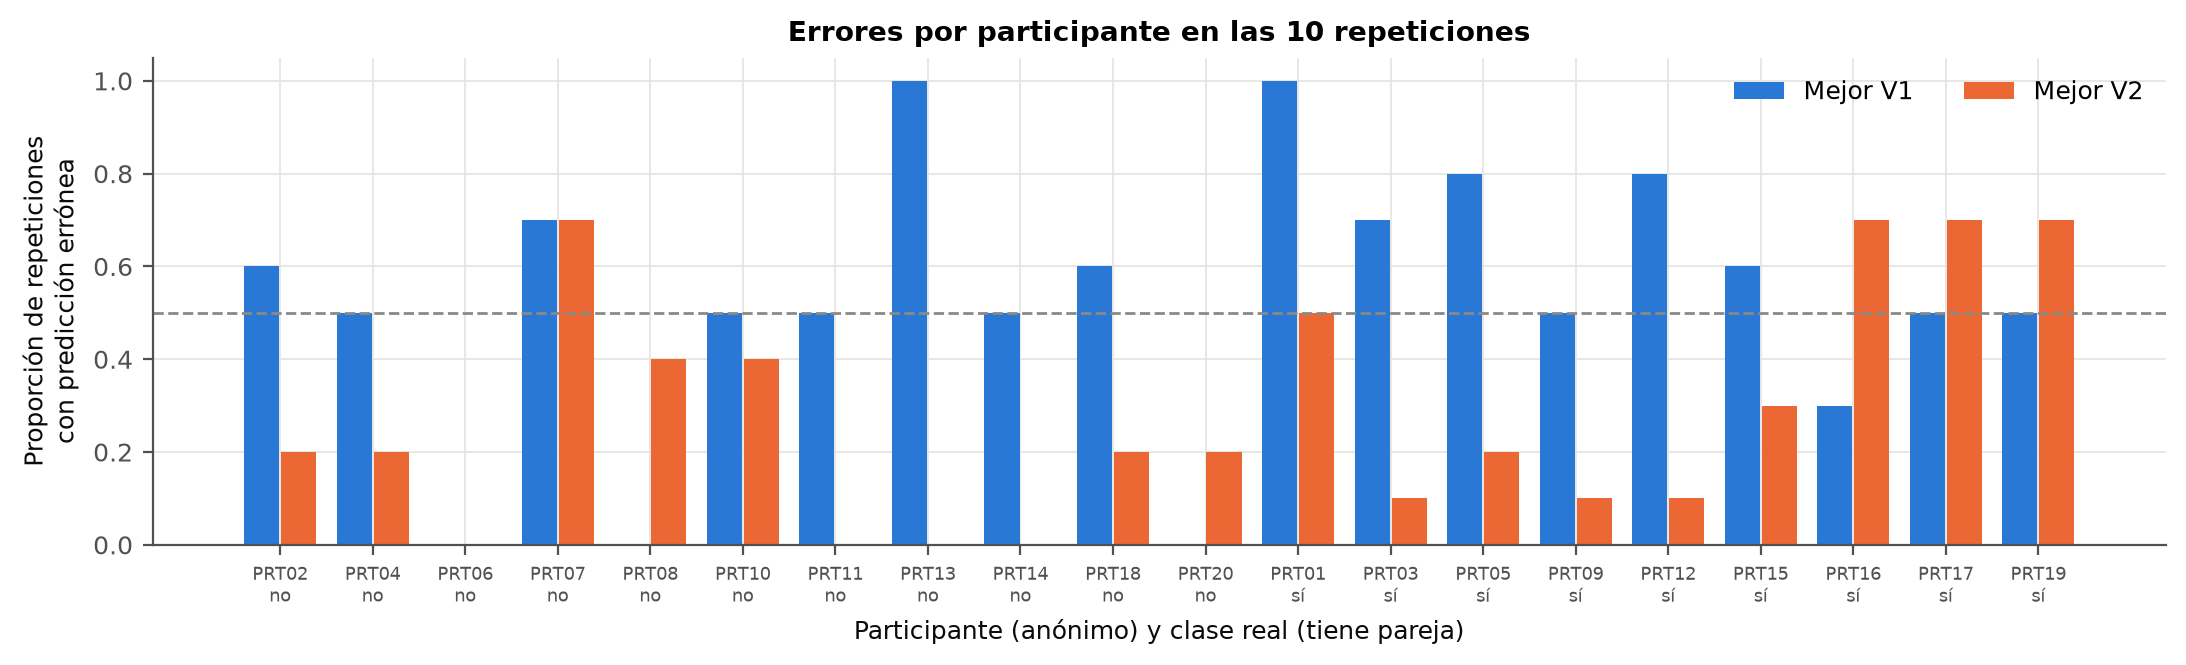

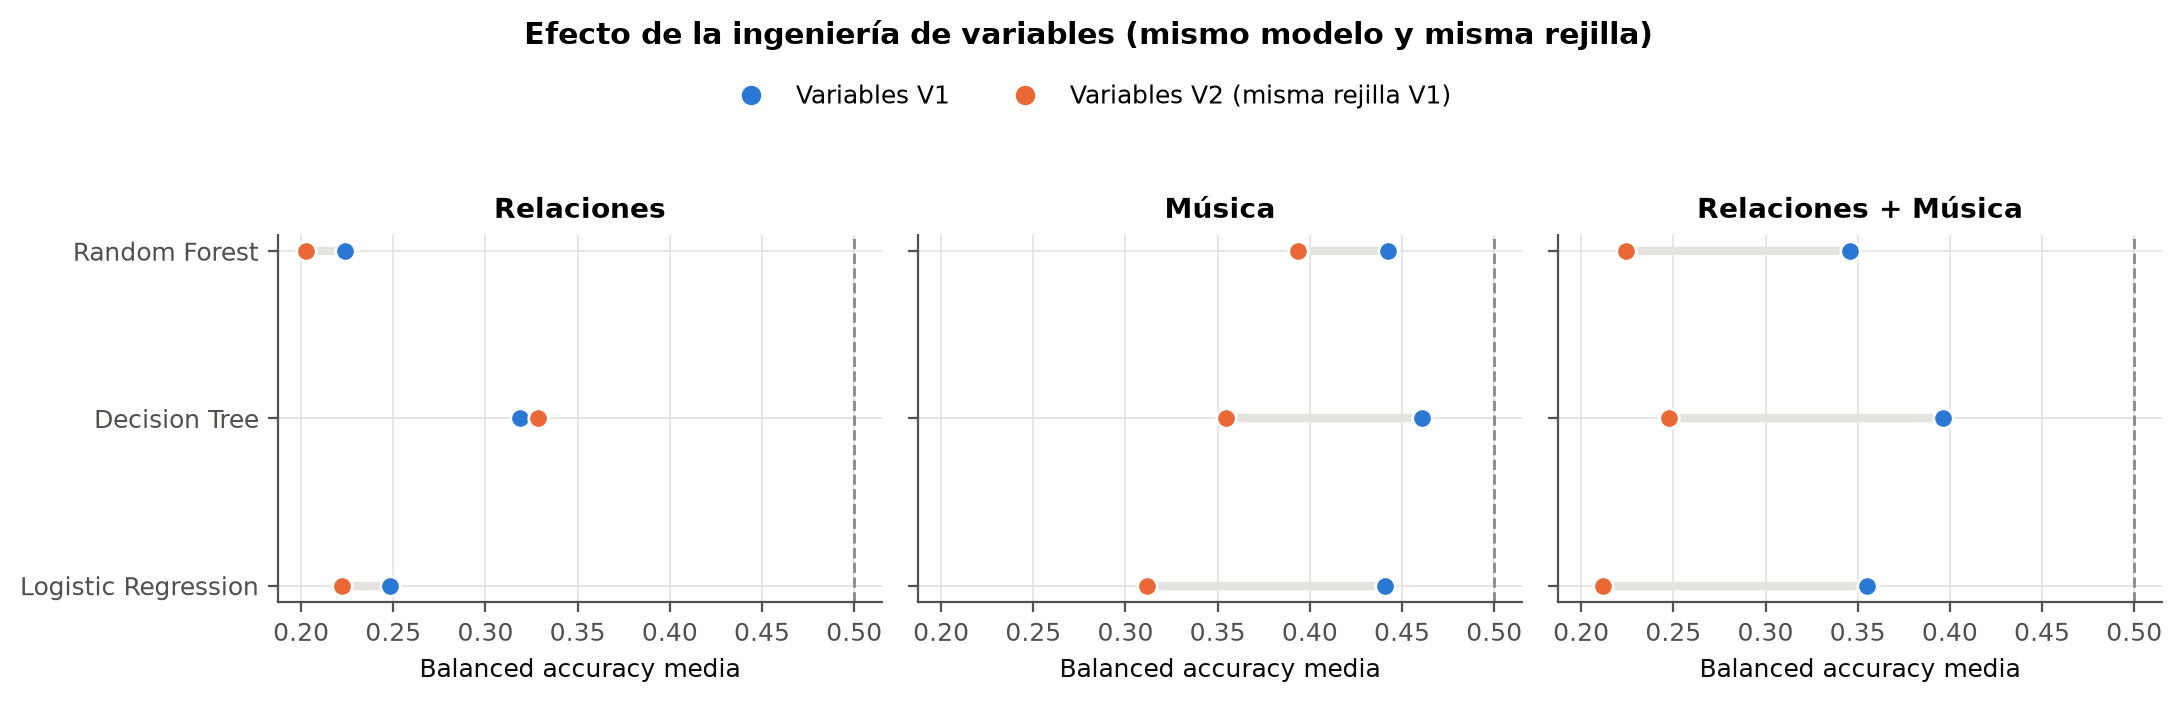

In [ ]:
display(Image(GRAF / "05_errores_por_participante.png", width=950))
display(Image(GRAF / "06_efecto_representacion_v2.png", width=950))

## 5. Variables / preguntas más informativas (con limitaciones)
* Asociación univariante **descriptiva** (Fisher / Mann-Whitney, corrección Benjamini-Hochberg).
* Ablación por pregunta dentro de la CV anidada del mejor candidato V2.
Con 20 personas ninguna de estas listas es estable ni generalizable.

In [ ]:
pd.read_csv(MET / "variables_informativas_v2.csv").head(10).round(3)

,variable,formulario,prueba,efecto (dif. proporcion o r),p_valor,prevalencia_o_media,q_valor_BH,frecuencia_seleccion_LogReg_pocas_variables
0,ord__mus_efecto_sueno,Musica,Mann-Whitney,-0.355,0.142,0.200,1.0,0.06
1,multi__cualidad_valorada=conexión emocional,Relaciones,Fisher exacta,0.394,0.175,0.450,1.0,0.22
2,num__mus_horas_dia,Musica,Mann-Whitney,-0.306,0.180,4.475,1.0,0.04
3,multi__cualidad_valorada=carácter y madurez,Relaciones,Fisher exacta,-0.273,0.218,0.150,1.0,0.02
4,ord__mus_ayuda_emociones,Musica,Mann-Whitney,-0.256,0.230,0.825,1.0,0.00
5,multi__mus_generos_frecuentes=rock,Musica,Fisher exacta,0.242,0.285,0.200,1.0,0.04
6,multi__mus_estrategia_animo_negativo=catarsis/...,Musica,Fisher exacta,0.242,0.285,0.200,1.0,0.14
7,multi__base_confianza=honestidad,Relaciones,Fisher exacta,-0.263,0.336,0.700,1.0,0.10
8,multi__demostracion_carino=contacto físico,Relaciones,Fisher exacta,0.283,0.362,0.400,1.0,0.06
9,multi__demostracion_carino=actos de servicio,Relaciones,Fisher exacta,0.303,0.370,0.500,1.0,0.06


In [ ]:
pd.read_csv(MET / "importancia_por_pregunta_ablacion.csv").head(10).round(3)

,escenario,modelo,pregunta_eliminada,formulario,caida_balanced_accuracy,caida_f1_macro,aumento_brier,balanced_accuracy_sin_pregunta,repeticiones_cv
0,relaciones_musica,SVM RBF,mus_actividades,Musica,0.057,0.058,0.033,0.632,5
1,relaciones_musica,SVM RBF,mus_usa_apple_music,Musica,0.057,0.055,0.028,0.632,5
2,relaciones_musica,SVM RBF,base_confianza,Relaciones,0.049,0.049,0.015,0.639,5
3,relaciones_musica,SVM RBF,resolucion_desacuerdos,Relaciones,0.049,0.053,0.012,0.639,5
4,relaciones_musica,SVM RBF,mus_prefiere,Musica,0.040,0.041,0.020,0.648,5
5,relaciones_musica,SVM RBF,mus_n_plataformas,Musica,0.040,0.041,0.010,0.648,5
6,relaciones_musica,SVM RBF,mus_horas_dia,Musica,0.038,0.039,0.006,0.651,5
7,relaciones_musica,SVM RBF,mus_usa_spotify,Musica,0.038,0.039,0.018,0.651,5
8,relaciones_musica,SVM RBF,definicion_respeto,Relaciones,0.029,0.032,0.022,0.660,5
9,relaciones_musica,SVM RBF,cita_ideal_cat,Relaciones,0.025,0.027,0.005,0.664,5


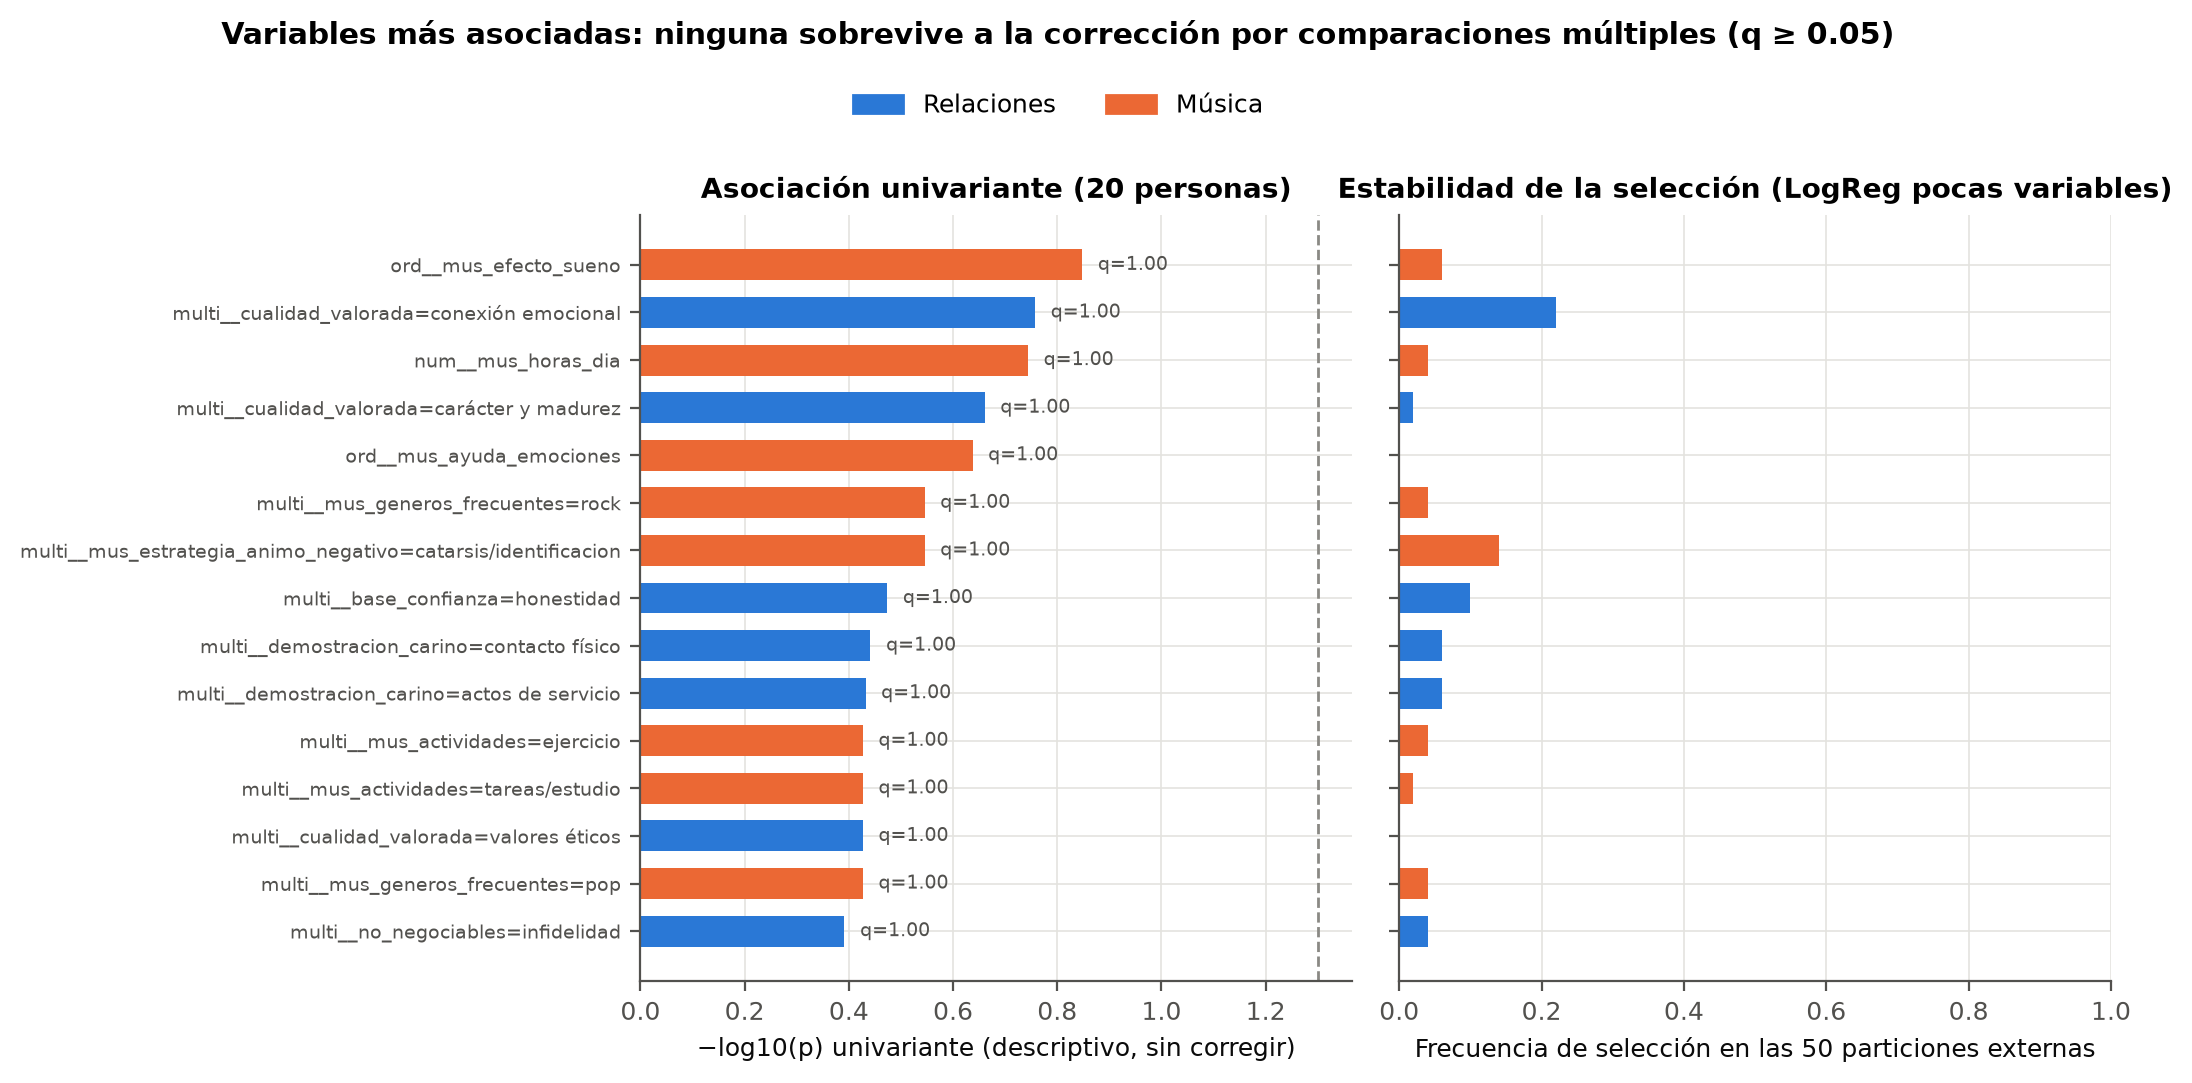

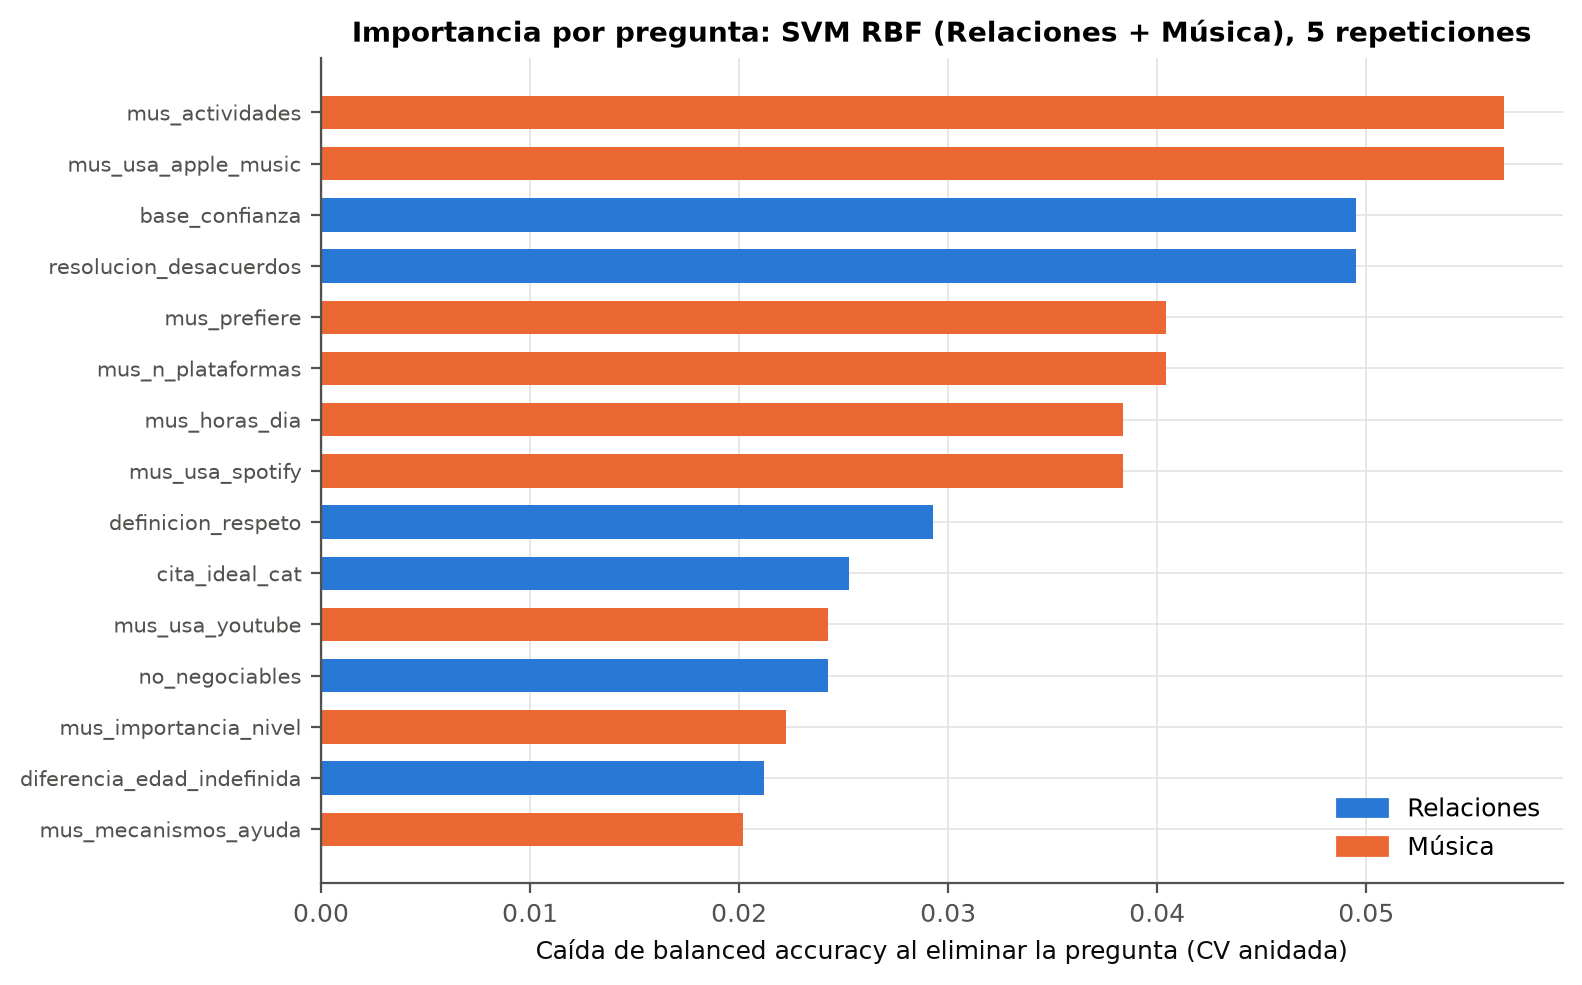

In [ ]:
display(Image(GRAF / "04_variables_informativas_y_estabilidad.png", width=950))
display(Image(GRAF / "08_importancia_por_pregunta.png", width=800))

## 6. Modelo guardado

In [ ]:
import joblib
obj = joblib.load(V2 / "modelos" / "mejor_pipeline_supervisado.joblib")
print(json.dumps({k: obj["metadatos"][k] for k in ["ronda_de_origen", "escenario", "modelo", "supera_dummy_de_forma_fiable", "advertencia"]}, indent=1, ensure_ascii=False))
p = obj["pipeline"].predict_proba(df[obj["variables_entrada"]])[:, 1]
print("probabilidades (ajuste con los 20; NO es una evaluación):", np.round(p, 2))

{
 "ronda_de_origen": "V2",
 "escenario": "relaciones_musica",
 "modelo": "SVM RBF",
 "supera_dummy_de_forma_fiable": false,
 "advertencia": "NO SUPERA AL DUMMY DE FORMA FIABLE: resultado exploratorio con 20 participantes (cumple los criterios pre-registrados, pero la prueba corregida por seleccion no es significativa). Uso exclusivamente academico; no usar para tomar decisiones sobre personas."
}
probabilidades (ajuste con los 20; NO es una evaluación): [0. 1. 0. 1. 0. 1. 1. 1. 0. 1. 1. 0. 1. 1. 0. 0. 0. 1. 0. 1.]


## 7. (Opcional) Recalcular el mejor candidato con 2 repeticiones

In [ ]:
if RECALCULAR:
    spec = u.ESCENARIOS_V2[v["mejor_v2"]["escenario"]]
    pipe, rej = u.candidatos_v2(spec)[v["mejor_v2"]["modelo"]]
    P, F, _ = u.evaluar(pipe, rej, df[u.columnas(spec)], y, 2)
    nuevo = u.metricas_rep(y, P, F).balanced_accuracy
    guardado = rep.loc[(v["mejor_v2"]["escenario"], v["mejor_v2"]["modelo"])].balanced_accuracy.iloc[:2]
    print("coincide con la caché:", np.allclose(nuevo.to_numpy(), guardado.to_numpy()))
else:
    print("RECALCULAR = False: se usan los resultados guardados")

RECALCULAR = False: se usan los resultados guardados


## 8. Conclusión
Ver `docs/INFORME_TECNICO.md` y `docs/RESUMEN_EJECUTIVO.md`. Esta ronda es **exploratoria**: cualquier mejora
debe confirmarse con participantes nuevos.

In [ ]:
print(json.dumps({k: v[k] for k in ["criterios_supera_dummy_mejor_v2", "supera_dummy_de_forma_fiable", "naturaleza"]}, indent=1, ensure_ascii=False))

{
 "criterios_supera_dummy_mejor_v2": {
  "a_BA_mayor_0.5_y_dummy": true,
  "b_mejor_que_dummy_en_8_de_10_repeticiones": true,
  "c_permutaciones_p_menor_0.05": true,
  "d_brier_no_peor_que_dummy": true
 },
 "supera_dummy_de_forma_fiable": false,
 "naturaleza": "exploratoria (segunda ronda sobre los mismos 20 participantes; no confirmatoria)"
}
